In [ ]:
# Library
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from google.colab import drive
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128

DDPM_EPOCHS = 20
DDPM_LR = 0.0002

TIMESTEPS = 1000
BETA_START = 0.0001
BETA_END = 0.02

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [2]:
# CP
from pathlib import Path

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/Model_Comparison"
    )
else:
    PROJECT_DIR = Path(".")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "ddpm"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Use Google Drive:", USE_GOOGLE_DRIVE)
print("Project Directory:", PROJECT_DIR)
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Output Directory:", OUTPUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Use Google Drive: True
Project Directory: /content/drive/MyDrive/Model_Comparison
Checkpoint Directory: /content/drive/MyDrive/Model_Comparison/checkpoints
Output Directory: /content/drive/MyDrive/Model_Comparison/outputs/ddpm


In [ ]:
# Dataset
transform = transforms.ToTensor()

train_original = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_original = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    train_original,
    test_original
])

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Total Dataset:", len(full_dataset))
print("Training Set:", len(train_dataset))
print("Validation Set:", len(val_dataset))
print("Testing Set:", len(test_dataset))


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.71MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.5MB/s]

Total Dataset: 70000
Training Set: 56000
Validation Set: 7000
Testing Set: 7000


In [ ]:
# Timestep Embedding

class SinusoidalPosEmb(nn.Module):

    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):

        half_dim = self.dim // 2

        emb_factor = math.log(10000) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(
                half_dim,
                device=t.device
            ) * -emb_factor
        )

        emb = t.float()[:, None] * emb[None, :]

        emb = torch.cat(
            [emb.sin(), emb.cos()],
            dim=1
        )

        return emb


# Residual Block

class ResBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        time_emb_dim
    ):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(
                time_emb_dim,
                out_channels
            )
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels)
        )

        self.residual_conv = (
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x, t_emb):

        h = self.block1(x)

        time_emb = self.time_mlp(t_emb)
        h = h + time_emb[:, :, None, None]

        h = self.block2(h)

        return F.silu(
            h + self.residual_conv(x)
        )


print("Timestep Embedding and ResBlock Ready!")


Timestep Embedding and ResBlock Ready!


In [ ]:
# U-Net Architecture

class DDPMUNet(nn.Module):

    def __init__(self, time_emb_dim=128):
        super().__init__()

        self.time_mlp = nn.Sequential(
            SinusoidalPosEmb(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU(),
            nn.Linear(time_emb_dim, time_emb_dim)
        )

        self.init_conv = nn.Conv2d(
            1, 32, kernel_size=3, padding=1
        )

        # Encoder

        self.down_block1 = ResBlock(
            32, 32, time_emb_dim
        )

        self.downsample1 = nn.Conv2d(
            32, 64,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.down_block2 = ResBlock(
            64, 64, time_emb_dim
        )

        self.downsample2 = nn.Conv2d(
            64, 128,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.mid_block = ResBlock(
            128, 128, time_emb_dim
        )

        # Decoder

        self.upsample1 = nn.ConvTranspose2d(
            128, 64,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up_block1 = ResBlock(
            128, 64, time_emb_dim
        )

        self.upsample2 = nn.ConvTranspose2d(
            64, 32,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up_block2 = ResBlock(
            64, 32, time_emb_dim
        )

        self.output_conv = nn.Conv2d(
            32, 1, kernel_size=1
        )

    def forward(self, x, t):

        t_emb = self.time_mlp(t)

        x = self.init_conv(x)

        # Encode

        h1 = self.down_block1(x, t_emb)
        x = self.downsample1(h1)

        h2 = self.down_block2(x, t_emb)
        x = self.downsample2(h2)

        x = self.mid_block(x, t_emb)

        # Decode + Skip Connections

        x = self.upsample1(x)
        x = torch.cat([x, h2], dim=1)
        x = self.up_block1(x, t_emb)

        x = self.upsample2(x)
        x = torch.cat([x, h1], dim=1)
        x = self.up_block2(x, t_emb)

        return self.output_conv(x)


ddpm_model = DDPMUNet(
    time_emb_dim=128
).to(DEVICE)


ddpm_model.eval()

with torch.no_grad():

    test_images = torch.randn(
        4, 1, 28, 28,
        device=DEVICE
    )

    test_timesteps = torch.randint(
        0, TIMESTEPS,
        (4,),
        device=DEVICE
    )

    predicted_noise = ddpm_model(
        test_images,
        test_timesteps
    )

print("Input Shape:", test_images.shape)
print("Predicted Noise Shape:", predicted_noise.shape)
print("DDPM U-Net Ready!")


Input Shape: torch.Size([4, 1, 28, 28])
Predicted Noise Shape: torch.Size([4, 1, 28, 28])
DDPM U-Net Ready!


In [ ]:
# Noise Schedule

betas = torch.linspace(
    BETA_START,
    BETA_END,
    TIMESTEPS,
    device=DEVICE
)

alphas = 1.0 - betas

alphas_cumprod = torch.cumprod(
    alphas,
    dim=0
)

sqrt_alphas_cumprod = torch.sqrt(
    alphas_cumprod
)

sqrt_one_minus_alphas_cumprod = torch.sqrt(
    1.0 - alphas_cumprod
)


# DDPM -> Forward Diffusion

def extract(schedule, t, x_shape):

    values = schedule.gather(0, t)

    return values.reshape(
        t.shape[0],
        *([1] * (len(x_shape) - 1))
    )


def q_sample(x_start, t, noise=None):

    if noise is None:
        noise = torch.randn_like(x_start)

    sqrt_alpha_bar = extract(
        sqrt_alphas_cumprod,
        t,
        x_start.shape
    )

    sqrt_one_minus_alpha_bar = extract(
        sqrt_one_minus_alphas_cumprod,
        t,
        x_start.shape
    )

    noisy_images = (
        sqrt_alpha_bar * x_start
        + sqrt_one_minus_alpha_bar * noise
    )

    return noisy_images, noise


print("Timesteps:", TIMESTEPS)
print("Beta Start:", betas[0].item())
print("Beta End:", betas[-1].item())
print("Forward Diffusion Function Ready!")


Timesteps: 1000
Beta Start: 9.999999747378752e-05
Beta End: 0.019999999552965164
Forward Diffusion Function Ready!


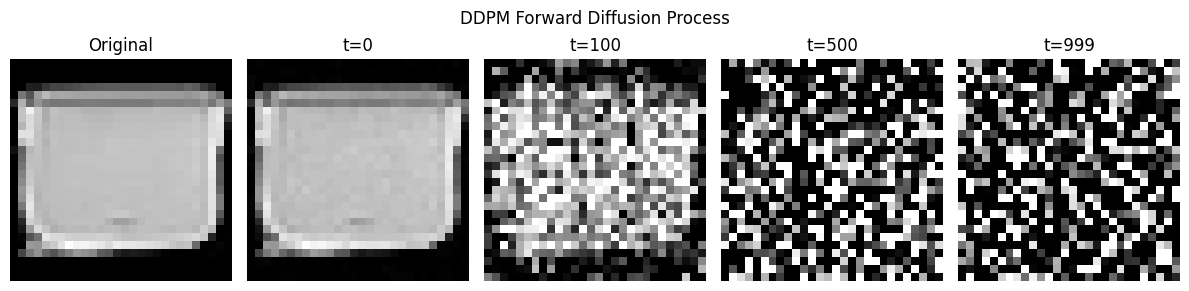

In [ ]:
# Forward Diffusion Preview

images, _ = next(iter(train_loader))

original_image = images[:1].to(DEVICE)

t_values = torch.tensor(
    [0, 100, 500, 999],
    device=DEVICE
)

test_batch = original_image.repeat(4, 1, 1, 1)

with torch.no_grad():

    noisy_images, _ = q_sample(
        test_batch,
        t_values
    )

fig, axes = plt.subplots(
    1, 5,
    figsize=(12, 3)
)

axes[0].imshow(
    original_image[0].cpu().squeeze().numpy(),
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[0].set_title("Original")
axes[0].axis("off")

for i in range(4):

    image = noisy_images[i].cpu().squeeze().numpy()

    axes[i + 1].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i + 1].set_title(
        f"t={t_values[i].item()}"
    )

    axes[i + 1].axis("off")

fig.suptitle("DDPM Forward Diffusion Process")
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "forward_diffusion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
# Training

ddpm_criterion = nn.MSELoss()

optimizer_ddpm = optim.Adam(
    ddpm_model.parameters(),
    lr=DDPM_LR
)

ddpm_train_losses = []
ddpm_val_losses = []
ddpm_epoch_times = []

best_ddpm_val_loss = float("inf")

checkpoint_path = CHECKPOINT_DIR / "ddpm.pt"
history_path = OUTPUT_DIR / "loss_history.csv"

print("DDPM CONFIGURATION")
print("Epochs:", DDPM_EPOCHS)
print("Learning Rate:", DDPM_LR)
print("Timesteps:", TIMESTEPS)
print("Device:", DEVICE)

for epoch in range(DDPM_EPOCHS):

    start_time = time.perf_counter()

    ddpm_model.train()

    total_train_loss = 0.0

    for images, _ in train_loader:

        images = images.to(DEVICE)
        batch_size = images.size(0)

        t = torch.randint(
            0,
            TIMESTEPS,
            (batch_size,),
            device=DEVICE
        ).long()

        noisy_images, noise = q_sample(
            images,
            t
        )

        optimizer_ddpm.zero_grad()

        predicted_noise = ddpm_model(
            noisy_images,
            t
        )

        loss = ddpm_criterion(
            predicted_noise,
            noise
        )

        loss.backward()
        optimizer_ddpm.step()

        total_train_loss += (
            loss.item() * batch_size
        )

    avg_train_loss = (
        total_train_loss / len(train_dataset)
    )


    ddpm_model.eval()
    total_val_loss = 0.0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(DEVICE)
            batch_size = images.size(0)

            t = torch.randint(
                0,
                TIMESTEPS,
                (batch_size,),
                device=DEVICE
            ).long()

            noisy_images, noise = q_sample(
                images,
                t
            )

            predicted_noise = ddpm_model(
                noisy_images,
                t
            )

            val_loss = ddpm_criterion(
                predicted_noise,
                noise
            )

            total_val_loss += (
                val_loss.item() * batch_size
            )

    avg_val_loss = (
        total_val_loss / len(val_dataset)
    )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    ddpm_train_losses.append(avg_train_loss)
    ddpm_val_losses.append(avg_val_loss)
    ddpm_epoch_times.append(epoch_time)

    if avg_val_loss < best_ddpm_val_loss:

        best_ddpm_val_loss = avg_val_loss

        best_ddpm_state = {
            key: value.detach().cpu().clone()
            for key, value in ddpm_model.state_dict().items()
        }

        torch.save(
            best_ddpm_state,
            checkpoint_path
        )

    pd.DataFrame({
        "epoch": range(1, epoch + 2),
        "train_loss": ddpm_train_losses,
        "val_loss": ddpm_val_losses,
        "epoch_time_s": ddpm_epoch_times
    }).to_csv(
        history_path,
        index=False
    )

    print(
        f"Epoch [{epoch+1}/{DDPM_EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Val Loss: {avg_val_loss:.6f} | "
        f"Time: {epoch_time:.2f}s"
    )

ddpm_model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )
)

ddpm_model.eval()

print("\nDDPM Training Complete!")
print(f"Best Validation Loss: {best_ddpm_val_loss:.6f}")
print(f"Average Epoch Time: {np.mean(ddpm_epoch_times):.2f}s")
print("Saved checkpoint:", checkpoint_path)

pd.DataFrame([{
    "model": "DDPM",
    "epochs": DDPM_EPOCHS,
    "timesteps": TIMESTEPS,
    "beta_start": BETA_START,
    "beta_end": BETA_END,
    "learning_rate": DDPM_LR,
    "seed": SEED,
    "best_val_loss": best_ddpm_val_loss,
    "mean_epoch_time_s": float(np.mean(ddpm_epoch_times))
}]).to_csv(
    OUTPUT_DIR / "training_summary.csv",
    index=False
)


DDPM CONFIGURATION
Epochs: 20
Learning Rate: 0.0002
Timesteps: 1000
Device: cuda
Epoch [1/20] | Train Loss: 0.087986 | Val Loss: 0.042217 | Time: 23.65s
Epoch [2/20] | Train Loss: 0.036936 | Val Loss: 0.035972 | Time: 24.43s
Epoch [3/20] | Train Loss: 0.033446 | Val Loss: 0.031657 | Time: 23.44s
Epoch [4/20] | Train Loss: 0.030484 | Val Loss: 0.029724 | Time: 23.37s
Epoch [5/20] | Train Loss: 0.029304 | Val Loss: 0.029181 | Time: 23.67s
Epoch [6/20] | Train Loss: 0.028084 | Val Loss: 0.027595 | Time: 23.79s
Epoch [7/20] | Train Loss: 0.027276 | Val Loss: 0.026578 | Time: 23.58s
Epoch [8/20] | Train Loss: 0.026564 | Val Loss: 0.027735 | Time: 23.87s
Epoch [9/20] | Train Loss: 0.026266 | Val Loss: 0.026049 | Time: 24.06s
Epoch [10/20] | Train Loss: 0.025555 | Val Loss: 0.026183 | Time: 24.13s
Epoch [11/20] | Train Loss: 0.025181 | Val Loss: 0.026789 | Time: 23.95s
Epoch [12/20] | Train Loss: 0.024927 | Val Loss: 0.025034 | Time: 24.02s
Epoch [13/20] | Train Loss: 0.024816 | Val Loss: 0.0

In [ ]:
# Reverse Diffusion

ddpm_model.eval()

alphas_cumprod_prev = torch.cat([
    torch.ones(1, device=DEVICE),
    alphas_cumprod[:-1]
])

posterior_variance = (
    betas
    * (1.0 - alphas_cumprod_prev)
    / (1.0 - alphas_cumprod)
)

posterior_variance = posterior_variance.clamp(
    min=1e-20
)


@torch.no_grad()
def p_sample(model, x, t):

    beta_t = extract(
        betas, t, x.shape
    )

    sqrt_one_minus_alpha_bar_t = extract(
        sqrt_one_minus_alphas_cumprod,
        t,
        x.shape
    )

    sqrt_recip_alpha_t = extract(
        torch.sqrt(1.0 / alphas),
        t,
        x.shape
    )

    predicted_noise = model(x, t)

    model_mean = sqrt_recip_alpha_t * (
        x
        - (
            beta_t
            / sqrt_one_minus_alpha_bar_t
        ) * predicted_noise
    )

    variance_t = extract(
        posterior_variance,
        t,
        x.shape
    )

    noise = torch.randn_like(x)

    nonzero_mask = (
        (t != 0).float().reshape(
            x.shape[0], 1, 1, 1
        )
    )

    return (
        model_mean
        + nonzero_mask
        * torch.sqrt(variance_t)
        * noise
    )


@torch.no_grad()
def ddpm_sample(model, num_samples=16):

    model.eval()

    x = torch.randn(
        num_samples,
        1,
        28,
        28,
        device=DEVICE
    )

    trajectory = {}

    trajectory[999] = x[0].cpu().clone()

    for step in reversed(range(TIMESTEPS)):

        t = torch.full(
            (num_samples,),
            step,
            device=DEVICE,
            dtype=torch.long
        )

        x = p_sample(
            model,
            x,
            t
        )

        if step in [800, 600, 400, 200, 100, 0]:

            trajectory[step] = (
                x[0].cpu().clone()
            )

    return x, trajectory


print("Reverse Diffusion Functions Ready!")


Reverse Diffusion Functions Ready!


Generated Images Shape: torch.Size([16, 1, 28, 28])
Trajectory Steps: [999, 800, 600, 400, 200, 100, 0]


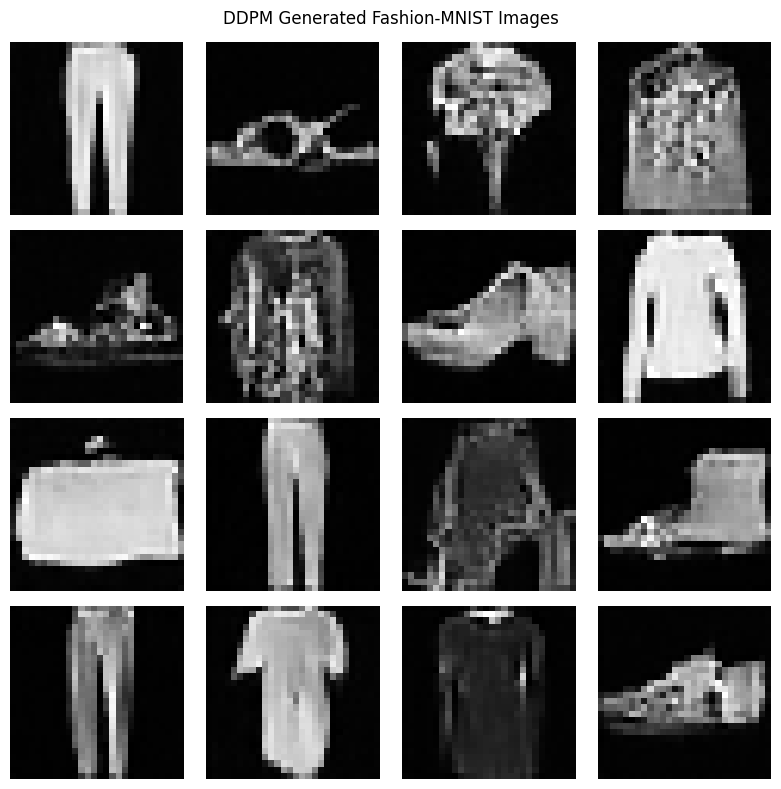

Saved: /content/drive/MyDrive/Model_Comparison/outputs/ddpm/random_sampling.png


In [ ]:
# Generate 16 Images

torch.manual_seed(SEED)

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

ddpm_model.eval()

ddpm_generated_images, ddpm_trajectory = ddpm_sample(
    ddpm_model,
    num_samples=16
)

print("Generated Images Shape:",
      ddpm_generated_images.shape)

print(
    "Trajectory Steps:",
    sorted(ddpm_trajectory.keys(), reverse=True)
)

fig, axes = plt.subplots(
    4, 4,
    figsize=(8, 8)
)

for i, ax in enumerate(axes.flat):

    image = (
        ddpm_generated_images[i]
        .cpu()
        .squeeze()
        .numpy()
    )

    ax.imshow(
        np.clip(image, 0, 1),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.axis("off")

fig.suptitle("DDPM Generated Fashion-MNIST Images")
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "random_sampling.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", OUTPUT_DIR / "random_sampling.png")


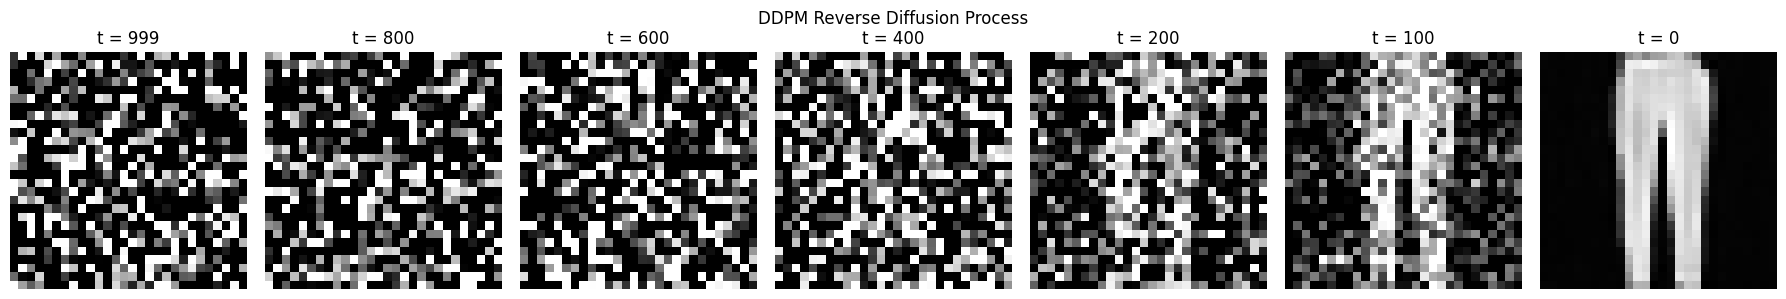

Saved: /content/drive/MyDrive/Model_Comparison/outputs/ddpm/reverse_trajectory.png


In [ ]:
# Reverse Diffusion Trajectory

trajectory_steps = sorted(
    ddpm_trajectory.keys(),
    reverse=True
)

fig, axes = plt.subplots(
    1,
    len(trajectory_steps),
    figsize=(18, 3)
)

for i, step in enumerate(trajectory_steps):

    image = ddpm_trajectory[step]

    image = (
        image.detach()
        .cpu()
        .squeeze()
        .numpy()
    )

    axes[i].imshow(
        np.clip(image, 0, 1),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(f"t = {step}")
    axes[i].axis("off")

fig.suptitle("DDPM Reverse Diffusion Process")
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "reverse_trajectory.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", OUTPUT_DIR / "reverse_trajectory.png")


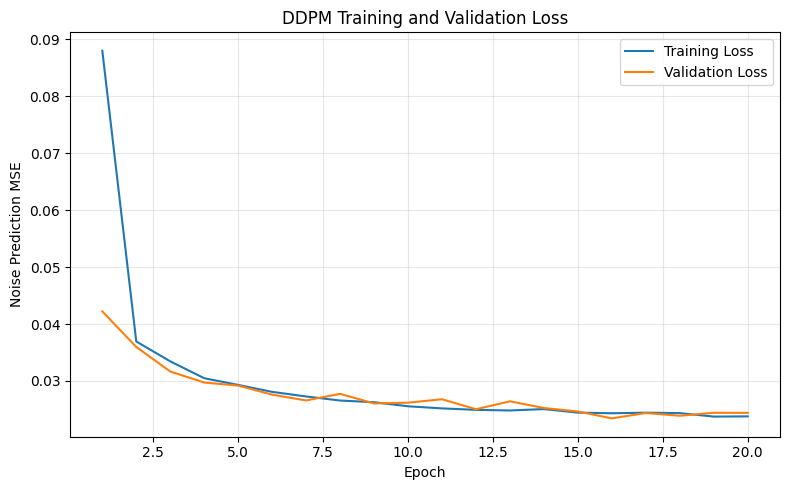

Saved: /content/drive/MyDrive/Model_Comparison/outputs/ddpm/training_loss.png


In [ ]:
#  Training Loss

fig, ax = plt.subplots(figsize=(8, 5))

epochs = range(1, len(ddpm_train_losses) + 1)

ax.plot(
    epochs,
    ddpm_train_losses,
    label="Training Loss"
)

ax.plot(
    epochs,
    ddpm_val_losses,
    label="Validation Loss"
)

ax.set_title("DDPM Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Noise Prediction MSE")

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", OUTPUT_DIR / "training_loss.png")
